# 正则化逻辑回归
在这个实验中，你将实现正则逻辑回归，以预测一家制造厂生产的微芯片是否通过质量保证(QA)测试。在QA检测期间，每个微芯片都要经过各种测试，以确保其正常工作

## 问题描述

假设你是这家工厂的产品经理，并且掌握了一些微芯片在两项不同测试中的测试结果。 
- 你希望根据这两项测试来确定这些微芯片应被接受还是拒绝。 
- 为帮助你做出决策，你拥有一个包含以往微芯片测试结果的数据集，可以利用它构建逻辑回归模型。

## 加载数据集并进行可视化

X_train shape:  (118, 2)
y_train shape:  (118,)
there are 118 training examples


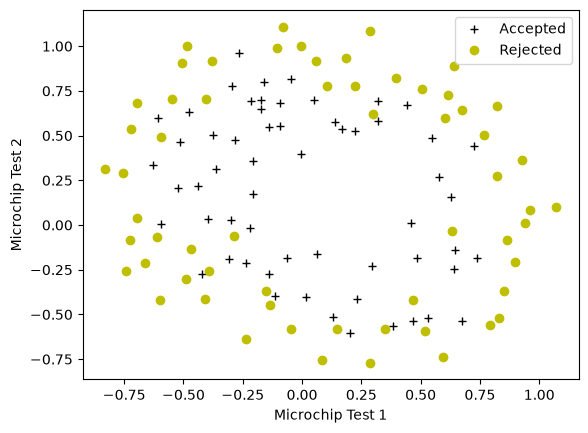

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from utils import * # 辅助函数
import copy
import math

def sigmod(z):
    return 1.0 / (1.0 + np.exp(-z))


# 加载数据集
X_train, y_train = load_data('data2.txt')

# 检查变量的维度
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("there are {} training examples".format(X_train.shape[0]))

# 可视化数据
plot_data(X_train, y_train[:], pos_label="Accepted", neg_label="Rejected")

# 设置 y 轴标签
plt.ylabel('Microchip Test 2') 
# 设置 x 轴标签
plt.xlabel('Microchip Test 1') 
plt.legend(loc="upper right")
plt.show()

观察图像我们发现，无法使用一条直线将数据集中的正例和反例分开，因此，直接应用逻辑回归在此数据集上的表现不会很好，因此逻辑回归只能找到线性决策边界

## 特征映射

更好地拟合数据的一种方法是从每个数据点创建更多特征。在提供的函数 `map_feature` 中，我们将把特征映射为由 $x_1$ 和 $x_2$ 构成的、最高六次的所有多项式项。

$$\mathrm{map\_feature}(x) = 
\left[\begin{array}{c}
x_1\\
x_2\\
x_1^2\\
x_1 x_2\\
x_2^2\\
x_1^3\\
\vdots\\
x_1 x_2^5\\
x_2^6\end{array}\right]$$

通过这一映射，包含两个特征（两项 QA 测试的得分）的向量被转换成了一个 27 维向量。 

>为什么是27维？
>你可以尝试枚举一下，按照次数枚举就行了

- 在这个更高维的特征向量上训练的逻辑回归分类器将具有更复杂的决策边界，在二维图中绘制出来时将呈现为非线性。 
- 我们已在 utils.py 中为你提供了 `map_feature` 函数。 

特征映射能够使我们构建表达能力更强的分类器，但它也更容易出现过拟合，所以需要加入正则化逻辑回归来防止过拟合。

## 正则化逻辑回归的代价函数

比起正常代价函数，多了一项 $$\frac{\lambda}{2m}  \sum_{j=0}^{n-1} w_j^2$$

In [36]:
def compute_cost_reg(X, y, w, b, lambda_ = 1):
    """
    计算所有样本的代价
    """
    m, n = X.shape
    total_cost = 0
    
    # np.log 默认底数为 e
    for i in range(m):
        total_cost += -y[i] * np.log(sigmod(np.dot(w.T, X[i]) + b)) - (1 - y[i]) * np.log(1 - sigmod(np.dot(w.T, X[i]) + b))

    total_cost /= m
    total_cost += lambda_ / (2 * m) * np.sum(w ** 2)
    
    return total_cost
    

In [37]:
# 验证实现
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1]) - 0.5
initial_b = 0.5
lambda_ = 0.5
cost = compute_cost_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print("Regularized cost :", cost)


Regularized cost : 0.6618252552483948


**预期输出**:
<table>
  <tr>
    <td> <b>正则化代价：<b></td>
    <td> 0.6618252552483948 </td> 
  </tr>
</table>

## 正则化逻辑回归的梯度下降

在正则化逻辑回归中，梯度下降的更新规则为：
$$
\begin{align*}
w &:= w - \alpha \frac{1}{m} X^T (h - y) - \frac{\lambda}{m} w \\

b &:= b - \alpha \frac{1}{m} (h - y)
\end{align*}
$$

In [38]:
# 计算梯度
def compute_gradient_reg(X, y, w, b, lambda_ = 1):
    """
    计算带正则化的逻辑回归的梯度
    """
    m, n = X.shape

    dj_db, dj_dw = 0, np.zeros(n)

    for i in range(m):
        tmp = sigmod(np.dot(X[i], w) + b) - y[i]
        dj_db += tmp;   
        for j in range(n):
            dj_dw[j] += tmp * X[i, j]
            
    # 添加正则化项
    dj_dw += lambda_ * w

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [39]:
# 验证 compute_gradient_reg 函数
# 特征映射
X_mapped = map_feature(X_train[:, 0], X_train[:, 1])
np.random.seed(1) 
initial_w  = np.random.rand(X_mapped.shape[1]) - 0.5 
initial_b = 0.5
 
lambda_ = 0.5
dj_dw, dj_db = compute_gradient_reg(X_mapped, y_train, initial_w, initial_b, lambda_)

print(f"dj_db: {dj_db}", )
print(f"First few elements of regularized dj_dw:\n {dj_dw[:4].tolist()}", )



dj_db: 0.07138288792343662
First few elements of regularized dj_dw:
 [-0.010386028450548701, 0.011409852883280122, 0.0536273463274574, 0.0031402782673134616]


**预期输出**:
<table>
  <tr>
    <td> <b>dj_db:</b>0.07138288792343656</td> </tr>
  <tr>
      <td> <b> 正则化后 dj_dw 的前几个元素：</b> </td> </tr>
   <tr>
   <td> [[-0.010386028450548701], [0.01140985288328012], [0.0536273463274574], [0.003140278267313462]] </td> 
  </tr>
</table>

In [40]:
# 使用梯度下降学习参数
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function, lambda_ = None):
    m, n = X.shape
    J_history = []
    w_history = []

    for i in range(num_iters):
        dj_dw, dj_db = gradient_function(X, y, w_in, b_in, lambda_)
        w_in = w_in - alpha * dj_dw
        b_in = b_in - alpha * dj_db
        if i < 100000:
            cost = cost_function(X, y, w_in, b_in, lambda_)
            J_history.append(cost)
        if i % math.ceil(num_iters / 10) == 0 or i == num_iters - 1:
            w_history.append(copy.deepcopy(w_in))
            print(f"Iteration {i:4d}: Cost {cost.item():.8f}")

    return w_in, b_in, J_history, w_history

In [41]:
np.random.seed(1)
initial_w = np.random.rand(X_mapped.shape[1])-0.5
initial_b = 1.

# 将正则化参数 lambda_ 设为 1（你可以尝试改变此值）
lambda_ = 0.01;                                          
# 一些梯度下降设置
iterations = 100000
alpha = 0.01

w,b, J_history,_ = gradient_descent(X_mapped, y_train, initial_w, initial_b, 
                                    alpha, iterations, compute_cost_reg, 
                                    compute_gradient_reg, lambda_)

Iteration    0: Cost 0.72101883
Iteration 10000: Cost 0.44532189
Iteration 20000: Cost 0.39965451
Iteration 30000: Cost 0.37947543
Iteration 40000: Cost 0.36847342
Iteration 50000: Cost 0.36170112
Iteration 60000: Cost 0.35717026
Iteration 70000: Cost 0.35394351
Iteration 80000: Cost 0.35152952
Iteration 90000: Cost 0.34965009
Iteration 99999: Cost 0.34813828


迭代10000次，预期输出，代价 < 0.5

迭代100000次，预期输出，代价 < 0.35

## 绘制决策边界

使用 `plot_decision_boundary` 函数绘制决策边界。网格中每个位置需要一个标量概率，`utils.py` 使用 `.item()` 将单元素数组转换为标量。修改辅助函数后，需要重新加载模块；下面的单元格会加载磁盘上的最新实现，已有的训练参数 `w`、`b` 无需重新计算。

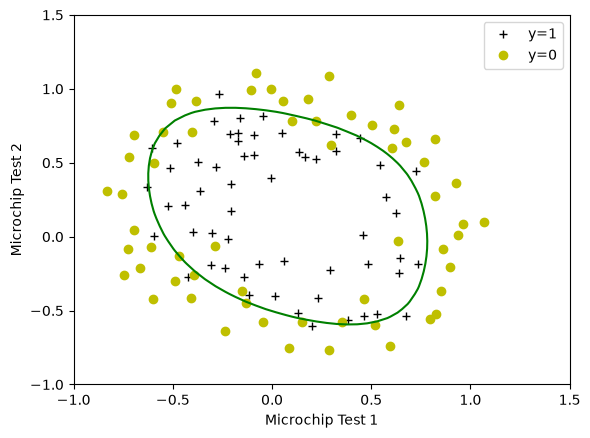

In [42]:
import importlib
import utils

importlib.reload(utils)
utils.plot_decision_boundary(w, b, X_mapped, y_train)
plt.xlabel('Microchip Test 1')
plt.ylabel('Microchip Test 2')
plt.legend(loc="upper right")
plt.show()

## 评估正则化逻辑回归模型

这里和前面是一样的，回去看之前的逻辑回归实验即可